# Stabilizer chain methods

Edit `bandage`, `preference`, `diagram_mode`, `face_colors`, and the `graph_*` options before running the cells using the **v2/.venv** kernel, with GAP on `PATH`.


In [1]:
import bce_v2 as c
from IPython.display import Markdown, display

bandage = [
    0, 0, 0,
    0, 0, 0,
    0, 0, 0,

    1, 0, 2,
    0, 0, 0,
    3, 0, 4,

    1, 0, 2,
    0, 0, 0,
    3, 0, 4,
]

preference = "memory"
diagram_mode = c.DiagramMode.OPPOSITE_CORNERS
face_colors = {
    'U': 'white', 'R': 'red', 'F': 'green',
    'D': 'yellow', 'L': 'orange', 'B': 'blue',
}

analysis = c.analyze_isotropy(bandage)
display(Markdown(
    "| Shapes | Isotropy group size | Total scrambles |\n"
    "| ---: | ---: | ---: |\n"
    f"| {analysis.loops.shape_count:,} | {analysis.group_order:,} | {analysis.colored_state_count:,} |"
))

| Shapes | Isotropy group size | Total scrambles |
| ---: | ---: | ---: |
| 4,062 | 40,131,624,960 | 163,014,660,587,520 |

Compile the staged guide. Graph rendering is a separate optional cell below.
Progress is printed while compiling. The 120-second optimization budget starts after a certified baseline is available.


# Solution from solved shape

This computational method covers all **40,131,624,960 reachable colored states** whose bandage shape is already the declared reference shape.

## Stages

In each stage's diagrams: face centers are colored to inform you how to orient the cube before algorithm application. Blocks already solved are dark grey. The block this stage requires you to identify is colored. Striped white color indicates a white sticker, plain white indicates unsolved sticker of any color.

| Stage | Avg moves | Worst moves |
| --- | ---: | ---: |
| Whole solution | 221.78 | 386 |
| Stage 1: Solve Edge UB | 3.88 | 6 |
| Stage 2: Solve Edge UF | 5.71 | 10 |
| Stage 3: Solve Edge UR | 6.33 | 11 |
| Stage 4: Solve Edge UL | 7.40 | 14 |
| Stage 5: Solve Corner UBR | 10.00 | 15 |
| Stage 6: Solve Edge DF | 11.62 | 19 |
| Stage 7: Solve Corner UFL | 14.33 | 24 |
| Stage 8: Solve Edge DL | 14.33 | 26 |
| Stage 9: Solve Edge DB | 12.00 | 20 |
| Stage 10: Orient Corner UBL | 13.33 | 20 |
| Stage 11: Solve Pair FL-DFL | 19.00 | 32 |
| Stage 12: Solve Pair BL-DBL | 37.33 | 56 |
| Stage 13: Solve Pair BR-DBR | 66.50 | 133 |

## Algorithms

Singmaster notation uses U/R/F/D/L/B, an apostrophe for an inverse turn, 2 for a half turn, x/y/z represent whole cube rotations 90° in the direction of an R/U/F move respectively. Structured recipes use `[A, B] = A B A⁻¹ B⁻¹`, `S^A = A⁻¹ S A`, and signed powers; a negative power executes the inverse algorithm.

| Turn sequence | Block action | Algorithm |
| --- | --- | --- |
| `M2: B2 L2 B2` | `(UBR UFL)(UL DL)([BR-DBR] [FL-DFL])` | `L2^B2` |
| `M3: B2 R2 B2` | `(UBL UFR)(UR DR)([BL-DBL] [FR-DFR])` | `R2^B2` |
| `M4: B2 F2 L2 R2` | `(UBL UFR)(UB DB)(UBR UFL)(UL DL)(UR DR)(UF DF)([BL-DBL] [FR-DFR])([BR-DBR] [FL-DFL])` | `B2 F2 L2 R2` |
| `M5: B F D2 F' B'` | `(UBL UFR)([BL-DBL] [FR-DFR])(DL DR)` | `D2^(F' B')` |
| `M7: B F' L F B'` | `(UBL UBR UFR UFL)(UB+ UL+ UF+ DL+)` | `L^(F B')` |
| `M8: B' F R F' B` | `(UBL UBR UFR UFL)(UB+ DR+ UF+ UR+)` | `R^(F' B)` |
| `M9: B' F' D2 F B` | `(UBR UFL)([BR-DBR] [FL-DFL])(DL DR)` | `D2^(F B)` |
| `M11: U B2 L2 B2 U'` | `(UBL UFR)(UF DL)([BR-DBR] [FL-DFL])` | `L2^(B2 U')` |
| `M12: U B2 R2 B2 U'` | `(UB DR)(UBR UFL)([BL-DBL] [FR-DFR])` | `R2^(B2 U')` |
| `M13: U' B2 L2 B2 U` | `(UBL UFR)(UB DL)([BR-DBR] [FL-DFL])` | `L2^(B2 U)` |
| `M14: U' B2 R2 B2 U` | `(UBR UFL)(UF DR)([BL-DBL] [FR-DFR])` | `R2^(B2 U)` |
| `M15: U2 B2 R2 B2 U2` | `(UBL UFR)(UL DR)([BL-DBL] [FR-DFR])` | `R2^(B2 U2)` |
| `M19: B F' D U' L' R` | `(UBL UFL UFR UBR)(UB+ DL DF+ UR)(UL UF+)([BL-DBL] [FL-DFL] [FR-DFR] [BR-DBR])(DB+ DR)` | `B F' D U' L' R` |
| `M22: B L U L' U' B'` | `(UBL UBR+)(UB+ UL UF+)(UFL UFR-)` | `[L, U]^B'` |
| `M23: B U' L2 B2 U' L` | `(UBL- UFR-)(UB+ DL UF)(UBR- UFL)(UL UR DB+)([BL-DBL] [FL-DFL] [BR-DBR])` | `B U' L2 B2 U' L` |
| `M28: B U B' U' L' B' L` | `(UBL+ UBR)(UB+)(UL DB+)(UFL-)` | `[B, U] B'^L` |
| `M29: U B F D2 F' B' U'` | `(UBR UFL)([BL-DBL] [FR-DFR])(DL DR)` | `D2^(F' B' U')` |
| `M31: B' F2 D R D' R' F2 B` | `(UBL- UBR)(UB+ UF DR+)(UFL+ UFR)` | `[D, R]^(F2 B)` |
| `M33: B L' B' R B L B' L' R' L` | `(UBR- UFR UFL+)` | `R^(L^B') R'^L` |
| `M35: B2 R2 B2 U L2 F2 L2 U' B2 R2 B2` | `(UBR UFL)([BL-DBL] [FR-DFR])(DR DF)` | `F2^(L2 U' R2^B2)` |
| `M36: B U L' U F' B2 U2 B2 U2 F U' L U' B'` | `(UBR- UFL- UFR-)([BL-DBL] [FL-DFL] [FR-DFR])` | `((B2 U2)2)^(F U' L U' B')` |
| `M37: B L U L' U' B' L2 F2 L2 B U L U' L' B' U' L2 F2 L2 U` | `(UBR+)(UFL-)` | `F2^(L2 [U, L]^B') F2^(L2 U)` |
| `M38: B U' L2 B2 U' L U2 B2 R2 B2 U2 L' U B2 L2 U B' U L' R B R' L B2 R2 B2 L' R B' R' L U'` | `([BL-DBL] [FR-DFR] [BR-DBR])` | `R2^((U2 L' U)^B2 L2 U B') R2^(B2 B'^(R' L) U')` |

### Shared piece recipes

| Piece | Turn sequence |
| --- | --- |
| `C1` | `L U L' U'` |
| `C2` | `B U' L2 B2 U' L` |
| `C3` | `B2 R2 B2` |
| `C4` | `B2 L' R B' R' L U'` |

| Algorithm | Recipe |
| --- | --- |
| `M2` | `(B2) (L2) (B2)^-1` |
| `M3` | `(B2) (R2) (B2)^-1` |
| `M4` | `B2 F2 L2 R2` |
| `M5` | `(B F) (D2) (B F)^-1` |
| `M7` | `(B F') (L) (B F')^-1` |
| `M8` | `(B' F) (R) (B' F)^-1` |
| `M9` | `(B' F') (D2) (B' F')^-1` |
| `M11` | `(U B2) (L2) (U B2)^-1` |
| `M12` | `(U B2) (R2) (U B2)^-1` |
| `M13` | `(U' B2) (L2) (U' B2)^-1` |
| `M14` | `(U' B2) (R2) (U' B2)^-1` |
| `M15` | `(U2 B2) (R2) (U2 B2)^-1` |
| `M19` | `B F' D U' L' R` |
| `M22` | `(B) (C1) (B)^-1` |
| `M23` | `C2` |
| `M28` | `y' (C1) y L' B' L` |
| `M29` | `(U B F) (D2) (U B F)^-1` |
| `M31` | `(B' F2) (x2 z' (C1) z x2) (B' F2)^-1` |
| `M33` | `B L' B' R x z (C1) z' x' R' L` |
| `M35` | `(C3 U L2) (F2) (C3 U L2)^-1` |
| `M36` | `(B U L' U F') (z (C3) z' U2) (B U L' U F')^-1` |
| `M37` | `B C1 B' x2 y (C3) y' x2 B C1^-1 B' U' x2 y (C3) y' x2 U` |
| `M38` | `C2 U2 C3 U2 C2^-1 C4^-1 R2 C4` |

## Stage 1: Solve Edge UB

This stage has 16 exact cases and 13 instruction families. It reduces the remaining possibilities from 40,131,624,960 to 2,508,226,560.

### Case 1

Skip — already correct

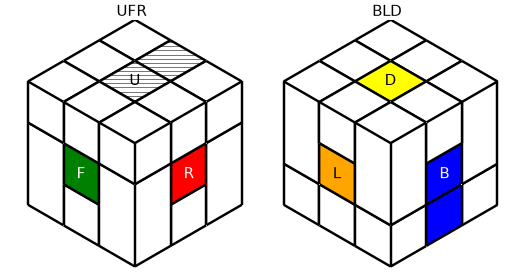

### Case 2

Execute `(U' (y' (M7) y)^-1)^-1: R L' B L R' U`.

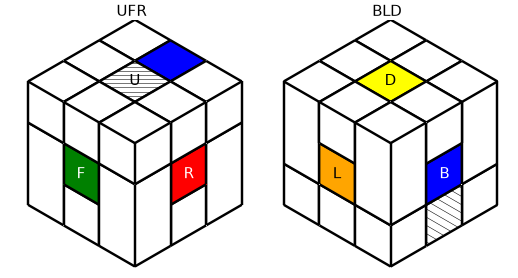

### Case 3

Execute `U: U`.

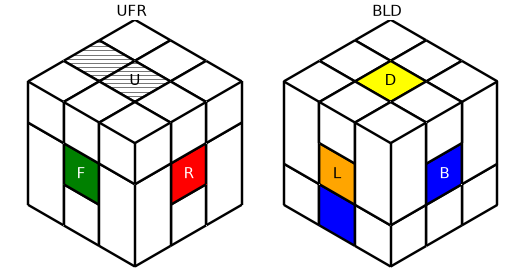

### Case 4

Execute `M7^-1: B F' L' F B'`.

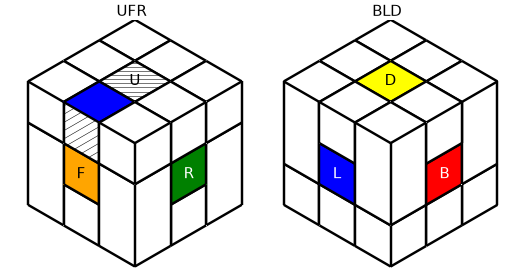

### Case 5

Execute `U': U'`.

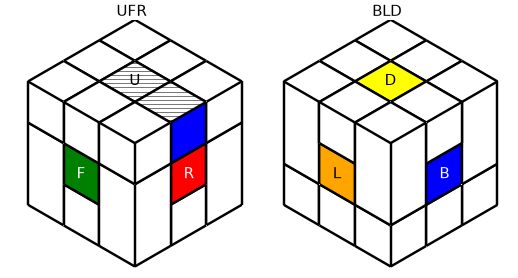

### Case 6

Execute `M7: B F' L F B'`.

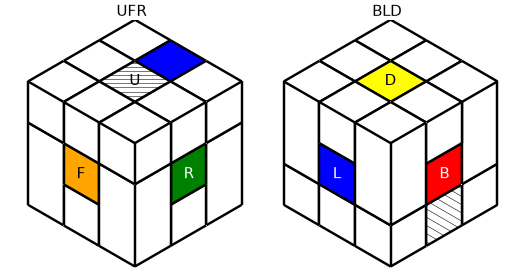

### Case 7

Execute `U2: U2`.

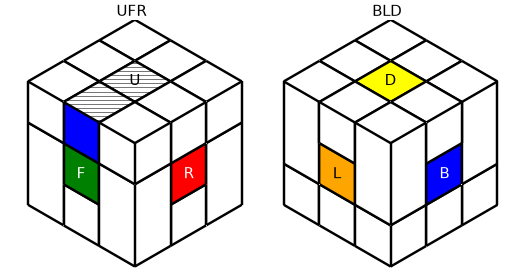

### Case 8

Execute `M22^-1: B U L U' L' B'`.

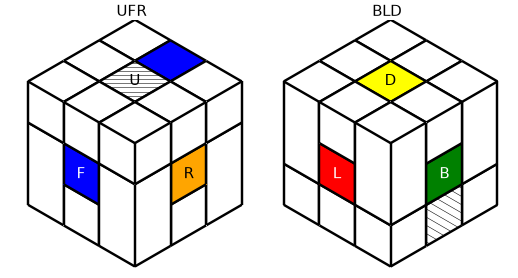

### Case 9

Execute `M3: B2 R2 B2`.

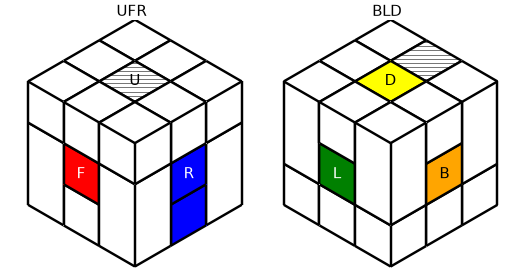

### Case 10

Execute `(U' y' (M7) y)^-1: R L' B' L R' U`.

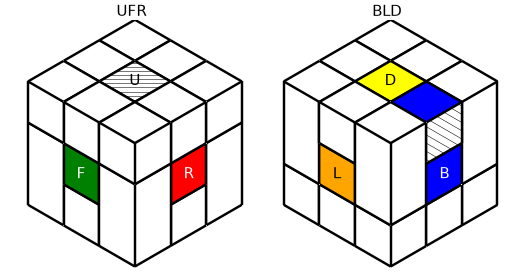

### Case 11

Execute `(U' y2 (M3) y2)^-1: F2 L2 F2 U`.

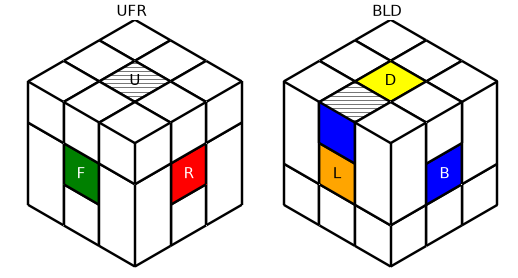

### Case 12

Execute `M8: B' F R F' B`.

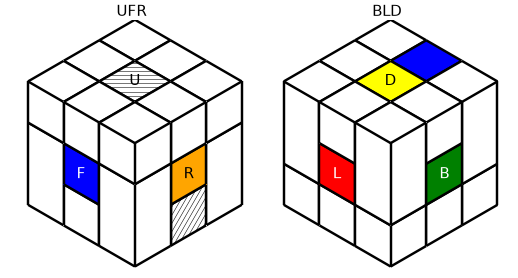

### Case 13

Execute `(U y2 (M2) y2)^-1: F2 R2 F2 U'`.

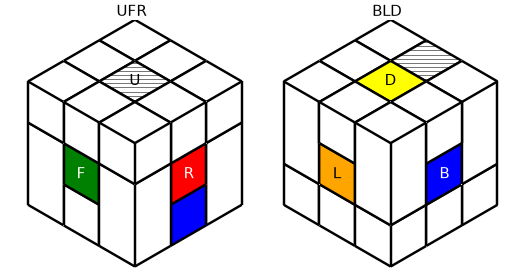

### Case 14

Execute `M7^-1: B F' L' F B'`.

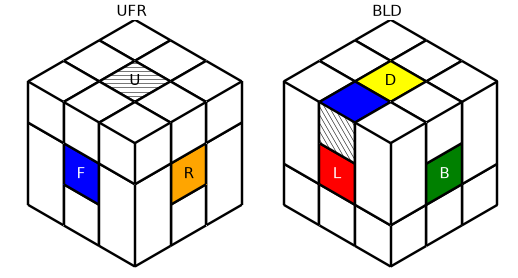

### Case 15

Execute `(U2 y (M2) y')^-1: L2 F2 L2 U2`.

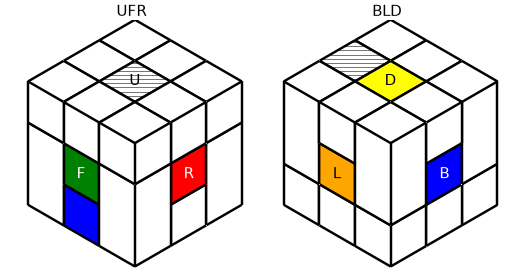

### Case 16

Execute `(U' (y' (M8) y)^-1)^-1: R' L F L' R U`.

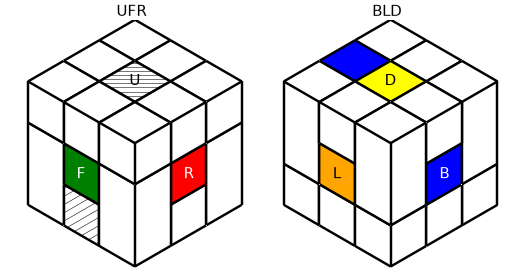

Also correct automatically after this stage: place Edge UB.

## Stage 2: Solve Edge UF

This stage has 14 exact cases and 13 instruction families. It reduces the remaining possibilities from 2,508,226,560 to 179,159,040.

### Case 1

Execute `(y' (M22) y U)^-1: U' R U B U' B' R'`.

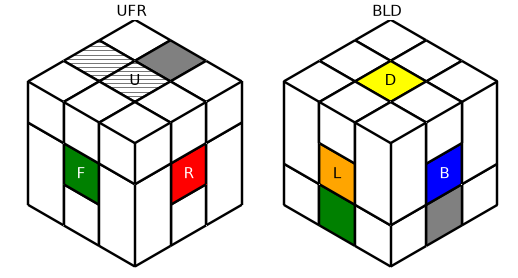

### Case 2

Execute `M8: B' F R F' B`.

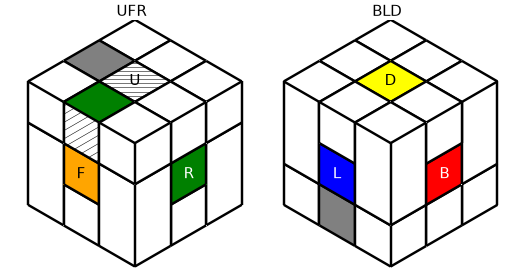

### Case 3

Execute `M22^-1: B U L U' L' B'`.

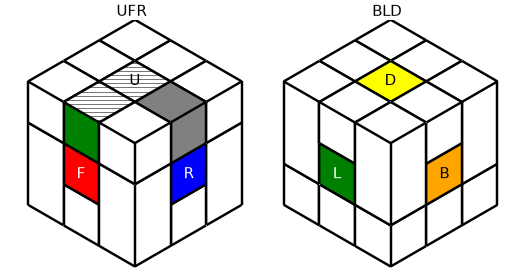

### Case 4

Execute `M8^-1: B' F R' F' B`.

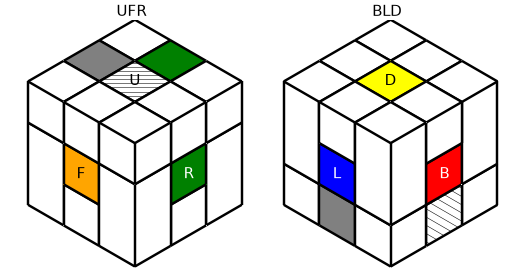

### Case 5

Skip — already correct

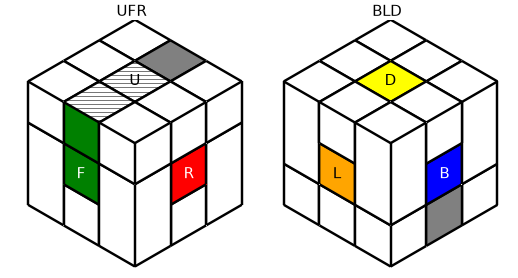

### Case 6

Execute `M28: B U B' U' L' B' L`.

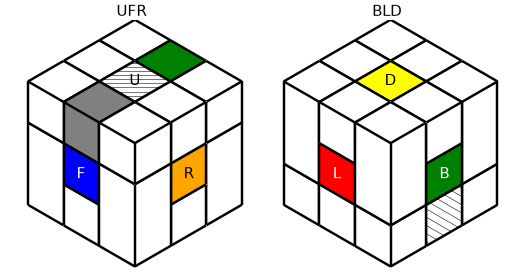

### Case 7

Execute `M15: U2 B2 R2 B2 U2`.

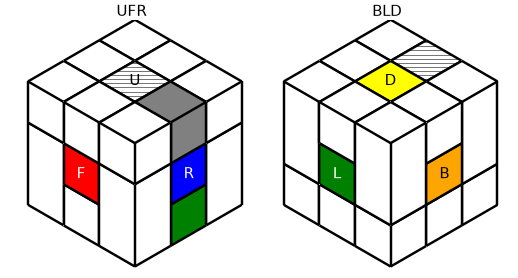

### Case 8

Execute `((y' (M8) y)^-1 y (M12) y')^-1: U L2 B2 L2 U' R' L F L' R`.

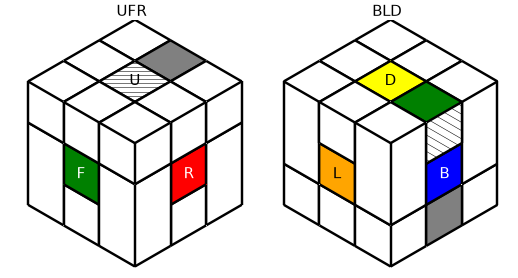

### Case 9

Execute `M11: U B2 L2 B2 U'`.

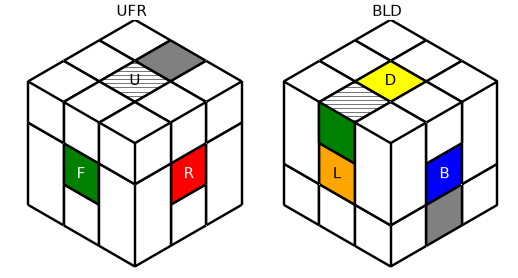

### Case 10

Execute `(M19^-1 M7^-1)^-1: B F' L D U' L' R`.

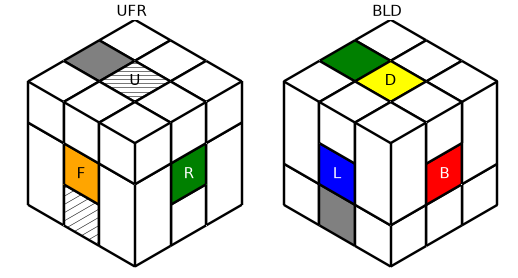

### Case 11

Execute `M14: U' B2 R2 B2 U`.

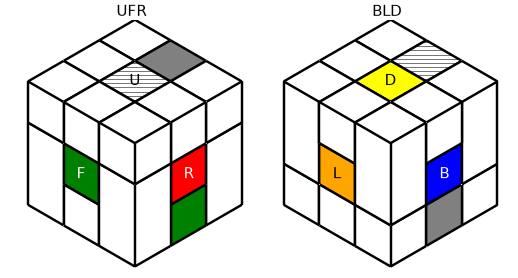

### Case 12

Execute `(y2 (M23) y2 U2)^-1: U2 R' U F2 R2 U F'`.

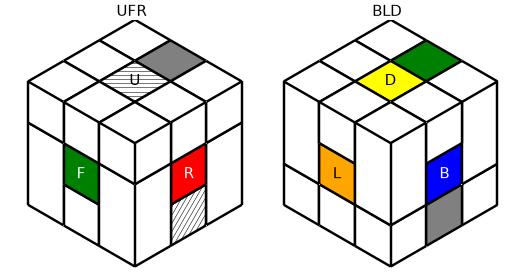

### Case 13

Execute `M2: B2 L2 B2`.

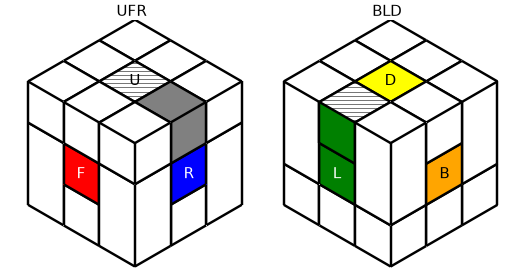

### Case 14

Execute `(U' (y2 (M23) y2)^-1 U')^-1: U F U' R2 F2 U' R U`.

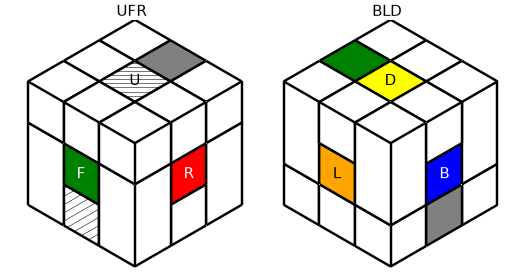

Also correct automatically after this stage: place Edge UF.

## Stage 3: Solve Edge UR

This stage has 12 exact cases and 11 instruction families. It reduces the remaining possibilities from 179,159,040 to 14,929,920.

### Case 1

Execute `(U2 (y2 (M7) y2)^-2)^-1: F B' R2 B F' U2`.

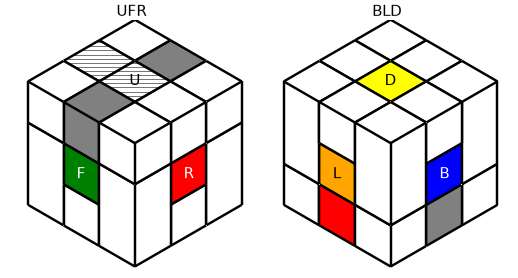

### Case 2

Execute `(U' (y' (M19) y)^-1)^-1: R L' D U' B' F U`.

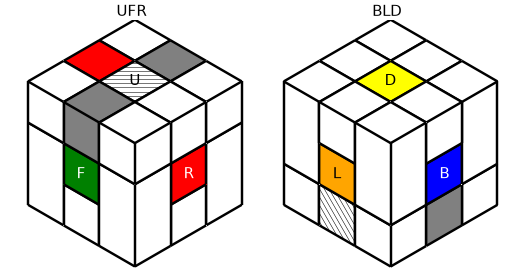

### Case 3

Skip — already correct

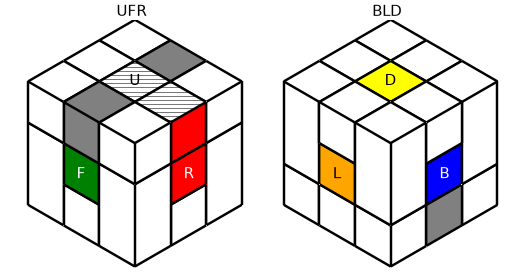

### Case 4

Execute `((y' (M8) y)^-1 y (M22) y')^-1: L U F U' F' L' R' L F L' R`.

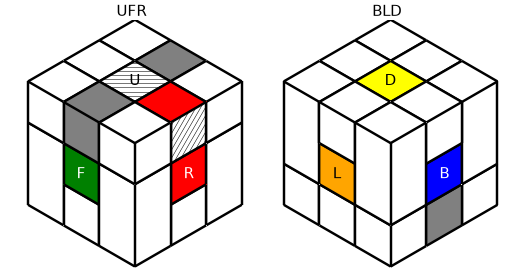

### Case 5

Execute `M14: U' B2 R2 B2 U`.

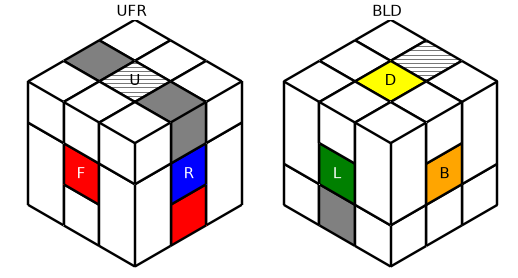

### Case 6

Execute `(y' (M19) y U)^-1: U' F' B U D' L R'`.

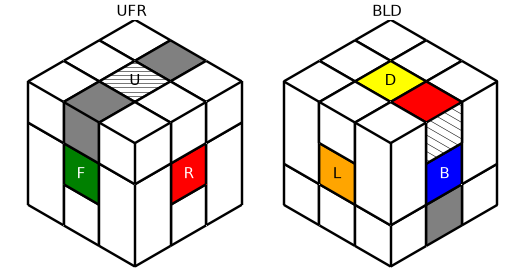

### Case 7

Execute `M15: U2 B2 R2 B2 U2`.

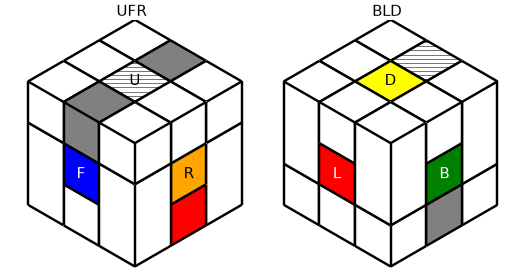

### Case 8

Execute `(U (y' (M19) y)^-1 U2)^-1: U2 R L' D U' B' F U'`.

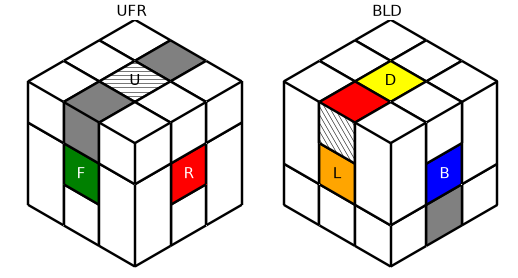

### Case 9

Execute `M2: B2 L2 B2`.

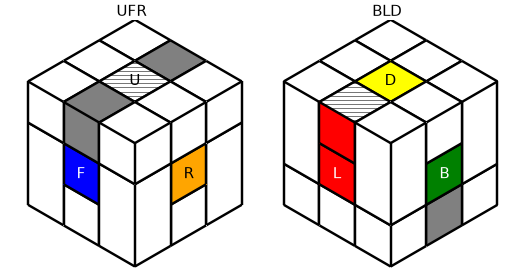

### Case 10

Execute `(y (M11) y' U' (y' (M19) y)^-1)^-1: R L' D U' B' F U2 L2 F2 L2 U'`.

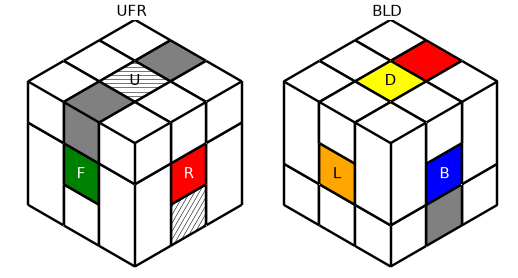

### Case 11

Execute `M11: U B2 L2 B2 U'`.

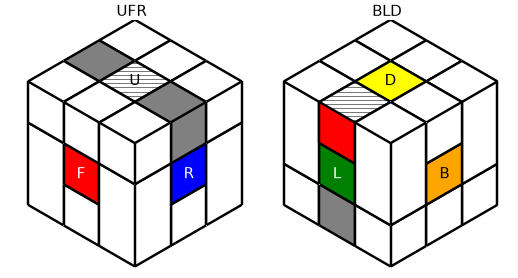

### Case 12

Execute `M31: B' F2 D R D' R' F2 B`.

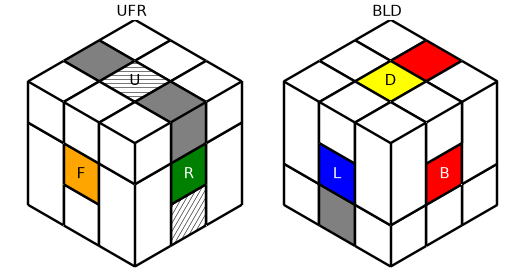

Also correct automatically after this stage: place Edge UR.

## Stage 4: Solve Edge UL

This stage has 10 exact cases and 9 instruction families. It reduces the remaining possibilities from 14,929,920 to 1,492,992.

### Case 1

Skip — already correct

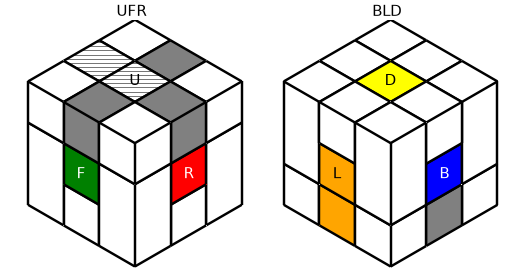

### Case 2

Execute `(y (M12) y' U (y' (M7) y)^-1 y' (M19) y y2 (M8) y2)^-1: F' B L' U D' B L R' L2 B2 L2 U'`.

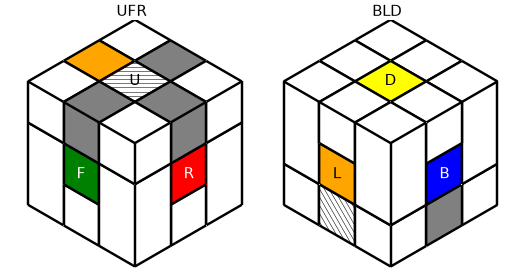

### Case 3

Execute `M12: U B2 R2 B2 U'`.

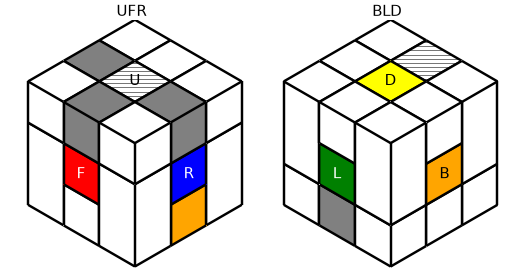

### Case 4

Execute `((y2 (M8) y2)^-1 (y' (M19) y)^-1 y' (M7) y U')^-1: U R L' B' D U' L B' F`.

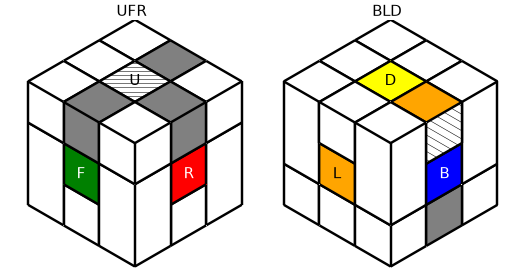

### Case 5

Execute `M3: B2 R2 B2`.

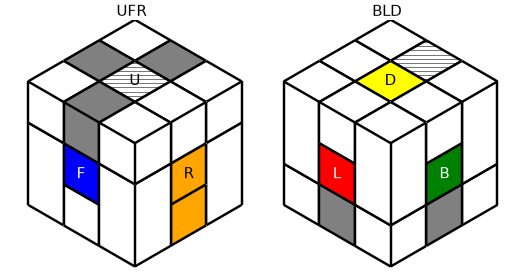

### Case 6

Execute `(U' (y' (M19) y)^-1 (y' (M31) y)^-1)^-1: R' L2 D F D' F' L2 R2 L' D U' B' F U`.

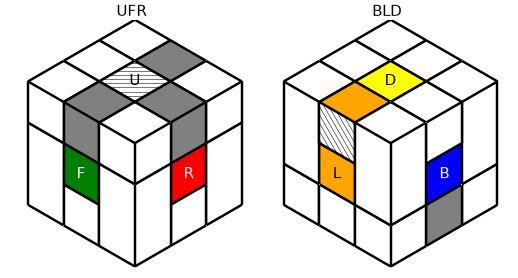

### Case 7

Execute `((y2 (M2) y2)^((U2 y2 (M2) y2)^-1))^-1: U2 F2 R2 F2 U2`.

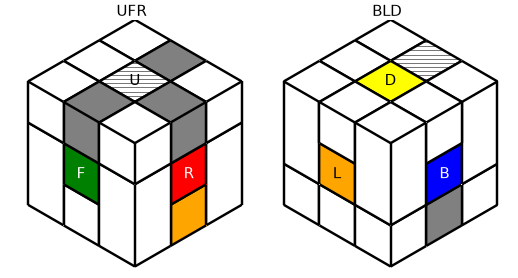

### Case 8

Execute `(U y2 (M7) y2 U' (y' (M7) y)^-1)^-1: R L' B L R' U F B' R' B F' U'`.

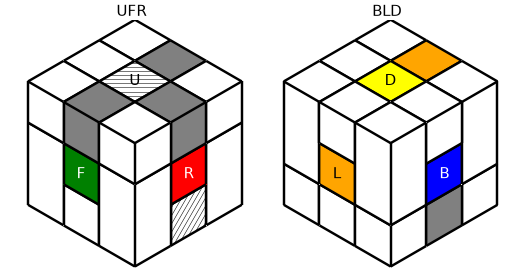

### Case 9

Execute `M13: U' B2 L2 B2 U`.

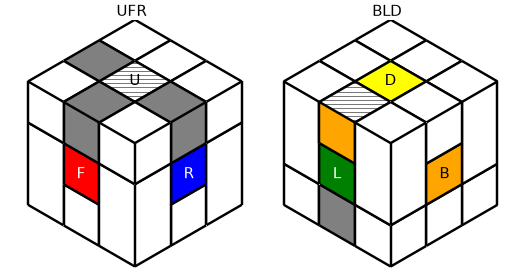

### Case 10

Execute `(M5^(M7^-1))^-1: B F' L F2 D2 F2 L' F B'`.

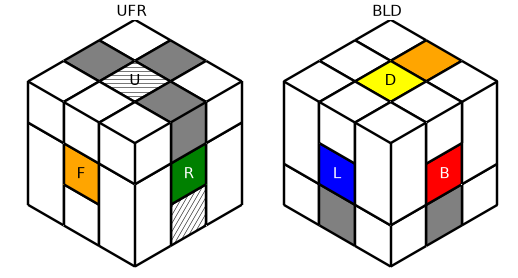

Also correct automatically after this stage: place Edge UL.

## Stage 5: Solve Corner UBR

This stage has 12 exact cases and 10 instruction families. It reduces the remaining possibilities from 1,492,992 to 124,416.

### Case 1

Execute `((U')^((y' (M4) y U)^-1))^-1: R2 L2 B2 F2 U F2 B2 L2 R2`.

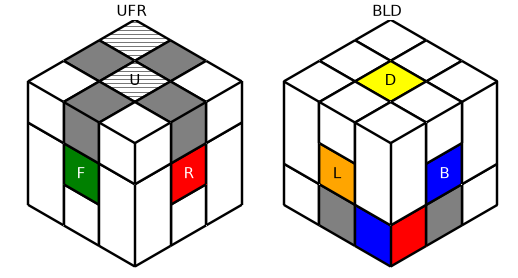

### Case 2

Execute `M33: B L' B' R B L B' L' R' L`.

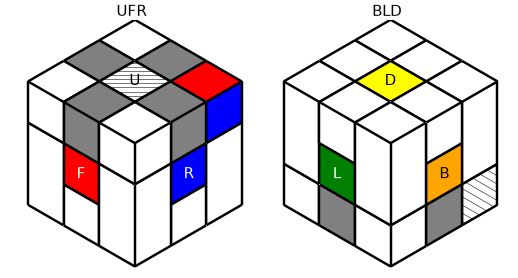

### Case 3

Execute `M22^-3: B U L U' L' U L U' L' U L U' L' B'`.

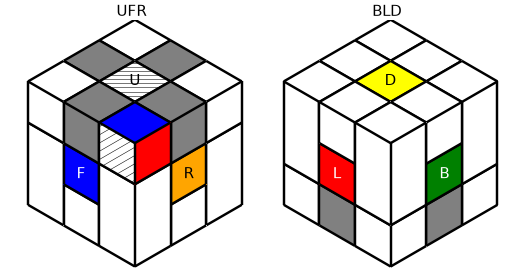

### Case 4

Skip — already correct

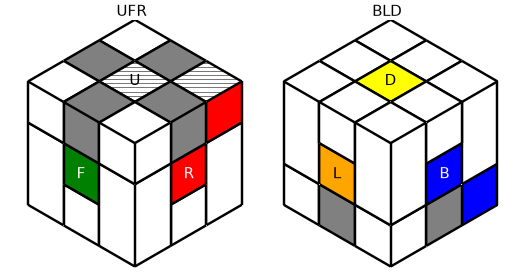

### Case 5

Execute `(y' (M5) y M33)^-1: L' R L B L' B' R' B L B' R L D2 L' R'`.

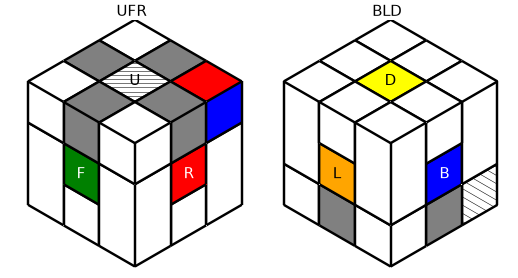

### Case 6

Execute `(y' (M5) y (y2 (M33) y2)^-1)^-1: F R' F' L F R F' R' L' R2 L D2 L' R'`.

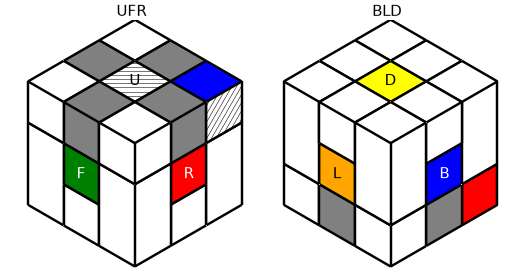

### Case 7

Execute `M5: B F D2 F' B'`.

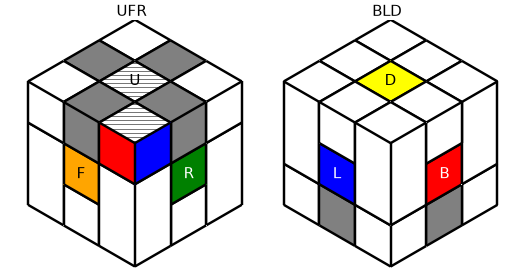

### Case 8

Execute `M33^-1: L' R L B L' B' R' B L B'`.

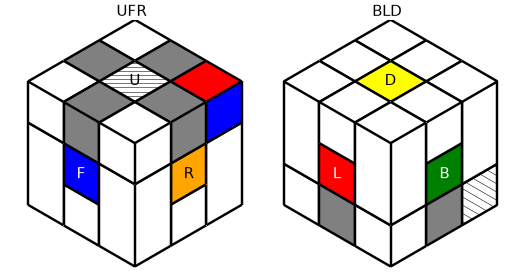

### Case 9

Execute `M33: B L' B' R B L B' L' R' L`.

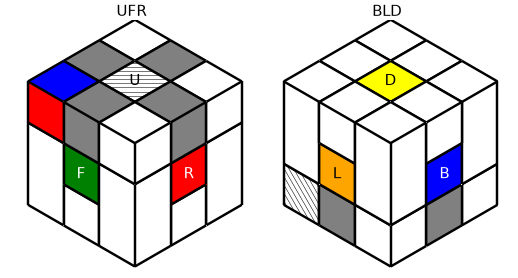

### Case 10

Execute `(U^(y' (M4) y))^-1: F2 B2 L2 R2 U' R2 L2 B2 F2`.

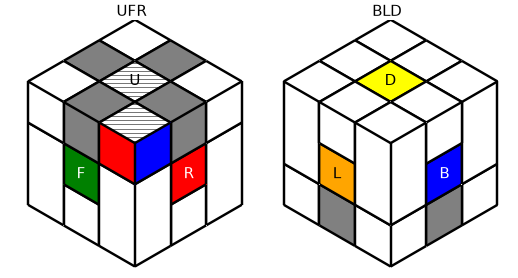

### Case 11

Execute `M22^-3: B U L U' L' U L U' L' U L U' L' B'`.

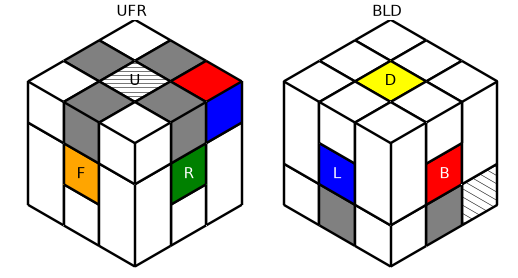

### Case 12

Execute `M33^-1: L' R L B L' B' R' B L B'`.

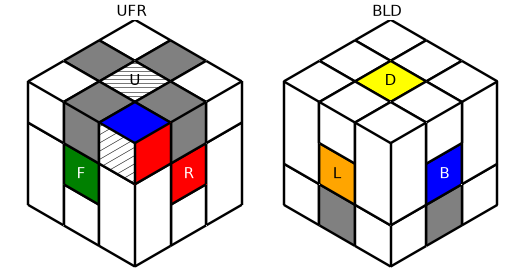

Also correct automatically after this stage: place Corner UBR.

## Stage 6: Solve Edge DF

This stage has 8 exact cases and 7 instruction families. It reduces the remaining possibilities from 124,416 to 15,552.

### Case 1

Execute `M9: B' F' D2 F B`.

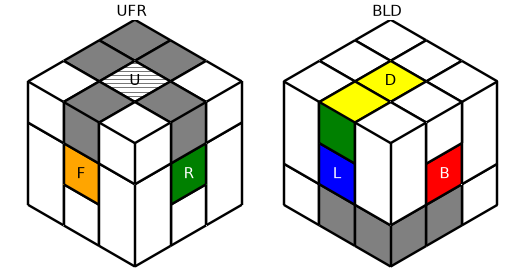

### Case 2

Execute `(y2 (M28) y2 y (M14) y' (y2 (M28) y2)^-1)^-1: F U F' U' R' F' R U' L2 B2 L2 U R' F R U F U' F'`.

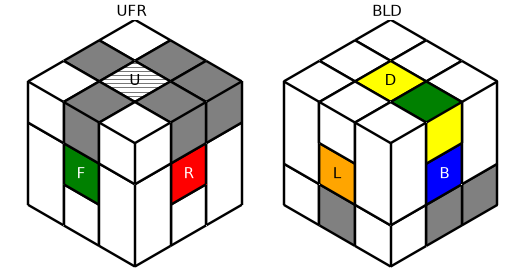

### Case 3

Execute `(M11 y (M2) y' M11)^-1: U B2 L2 B2 U' L2 F2 L2 U B2 L2 B2 U'`.

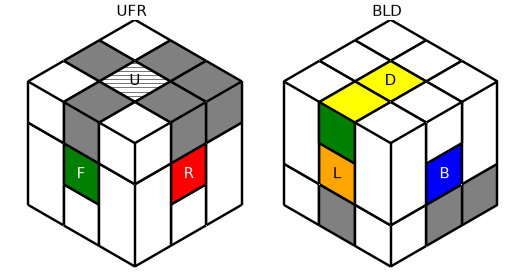

### Case 4

Execute `(U y' (M8) y y2 (M3) y2 (y' (M8) y)^-1 U')^-1: U R' L F L' R F2 L2 F2 R' L F' L' R U'`.

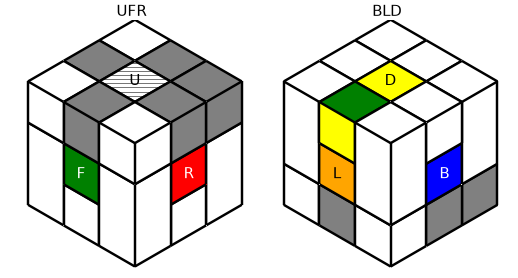

### Case 5

Execute `((y2 (M2) y2)^((y (M2) y' U')^-1))^-1: L2 F2 L2 U' F2 R2 F2 U L2 F2 L2`.

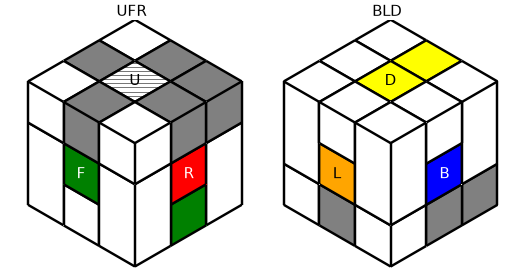

### Case 6

Execute `((y' (M8) y)^-1 y2 (M2) y2 y' (M8) y)^-1: R' L F' L' R F2 R2 F2 R' L F L' R`.

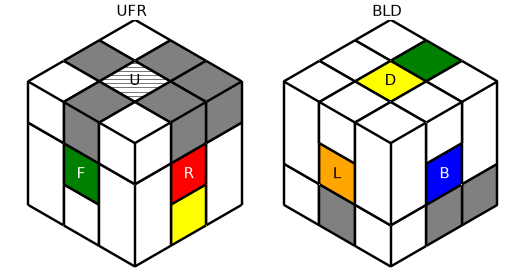

### Case 7

Skip — already correct

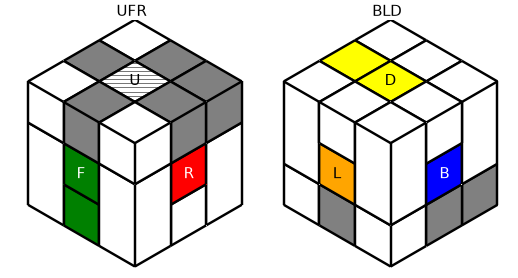

### Case 8

Execute `(((M9^(M8^-1) M13)^-1)^M8)^-1: B' F' D2 F2 R' F' B U' B2 L2 B2 U B' F R F' B`.

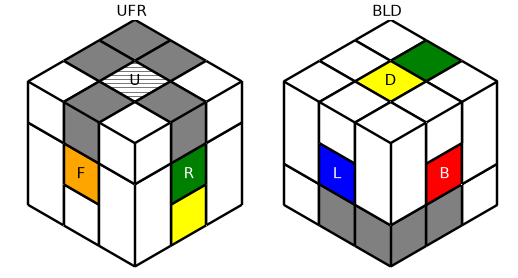

Also correct automatically after this stage: place Edge DF.

## Stage 7: Solve Corner UFL

This stage has 9 exact cases and 8 instruction families. It reduces the remaining possibilities from 15,552 to 1,728.

### Case 1

Execute `M33^-1: L' R L B L' B' R' B L B'`.

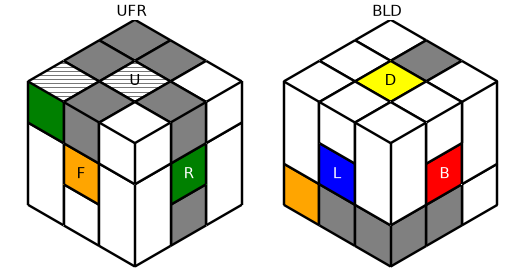

### Case 2

Execute `M36: B U L' U F' B2 U2 B2 U2 F U' L U' B'`.

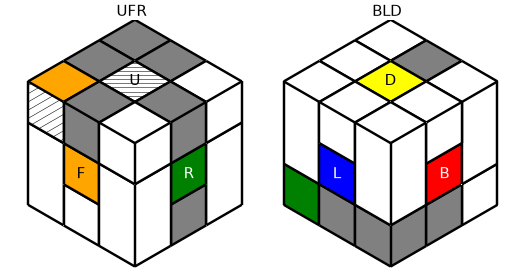

### Case 3

Execute `[M28^-1, M3]: L' B L U B U' B R2 B' U B' U' L' B' L B2 R2 B2`.

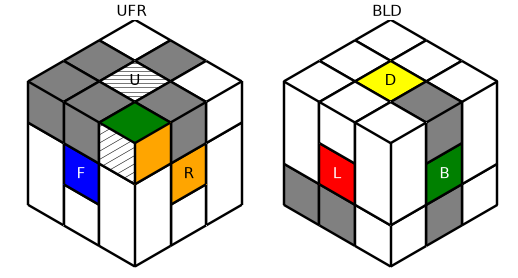

### Case 4

Skip — already correct

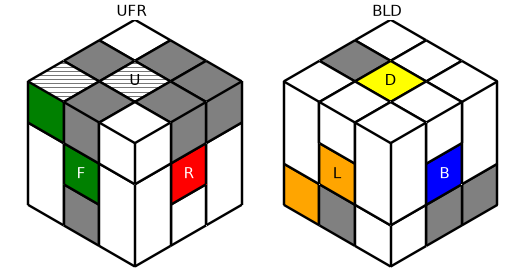

### Case 5

Execute `(M36^-1 M33^-1)^-1: B L' B' R B L B' L' R' L B U L' U F' B2 U2 B2 U2 F U' L U' B'`.

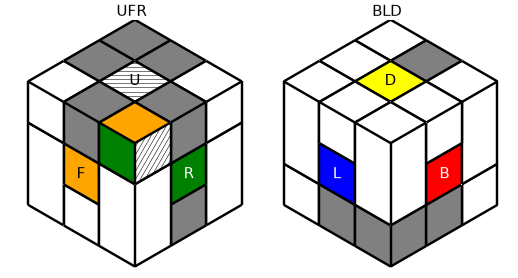

### Case 6

Execute `(M33 M36)^-1: B U L' U F' U2 B2 U2 B2 F U' L U' B' L' R L B L' B' R' B L B'`.

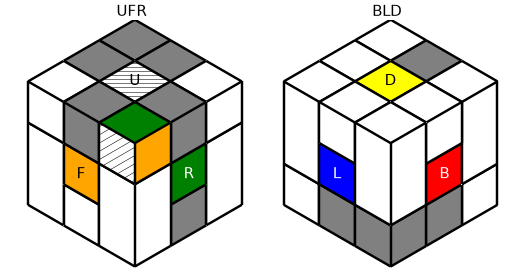

### Case 7

Execute `((y' (M33) y)^(M3^-1))^-1: B2 R2 B F B R B' R' F' R B R' B2 R2 B2`.

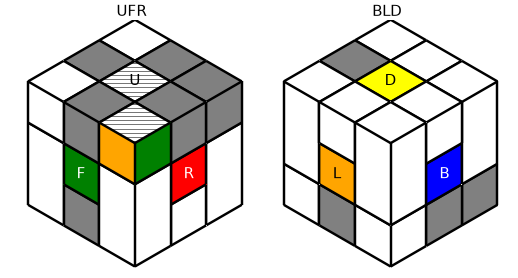

### Case 8

Execute `M33: B L' B' R B L B' L' R' L`.

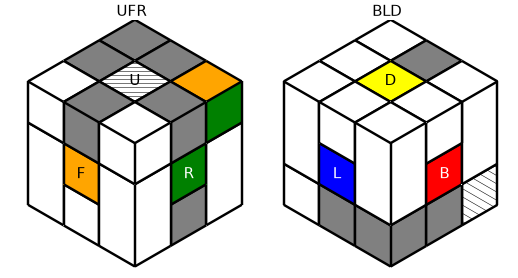

### Case 9

Execute `M36^-1: B U L' U F' U2 B2 U2 B2 F U' L U' B'`.

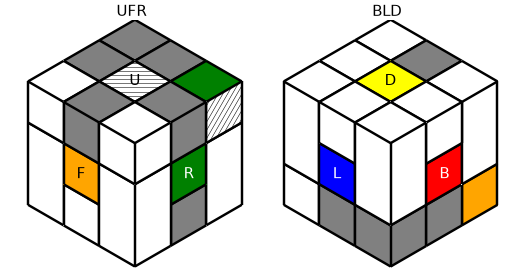

Also correct automatically after this stage: place Corner UFL.

## Stage 8: Solve Edge DL

This stage has 6 exact cases and 5 instruction families. It reduces the remaining possibilities from 1,728 to 288.

### Case 1

Execute `(y' (M11) y y2 (M3) y2 y' (M11) y)^-1: U R2 B2 R2 U' F2 L2 F2 U R2 B2 R2 U'`.

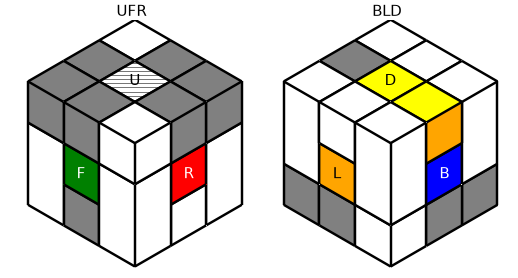

### Case 2

Execute `(U (y' (M7) y)^-1 y2 (M3) y2 y' (M7) y U')^-1: U R L' B' L R' F2 L2 F2 R L' B L R' U'`.

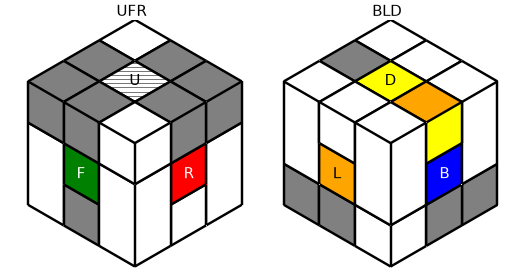

### Case 3

Skip — already correct

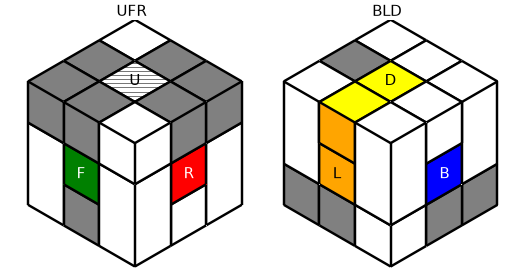

### Case 4

Execute `((((y' (M9) y)^((y' (M8) y)^-1) y' (M13) y)^-1)^((y2 (M3) y2 U2)^-1))^-1: F2 L2 F2 U2 R' L F L2 D2 L2 F' L' R U' R2 B2 R2 U' F2 L2 F2`.

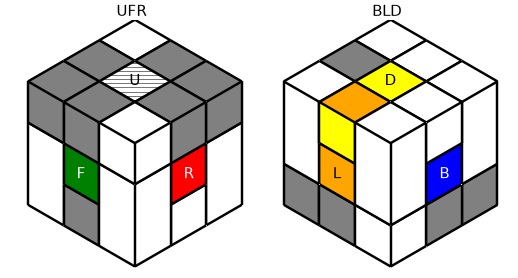

### Case 5

Execute `((y2 (M3) y2)^((y2 (M2) y2 U2)^-1))^-1: F2 R2 F2 U2 F2 L2 F2 U2 F2 R2 F2`.

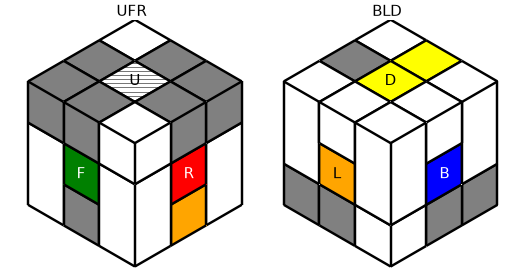

### Case 6

Execute `(U (y' (M7) y)^-1 y2 (M3) y2 y' (M7) y U' y (M35) y')^-1: L2 B2 L2 U F2 R2 F2 U' L2 B2 L2 U R L' B' L R' F2 L2 F2 R L' B L R' U'`.

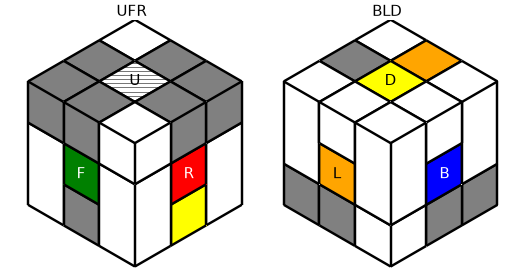

Also correct automatically after this stage: place Edge DL.

## Stage 9: Solve Edge DB

This stage has 4 exact cases and 3 instruction families. It reduces the remaining possibilities from 288 to 72.

### Case 1

Skip — already correct

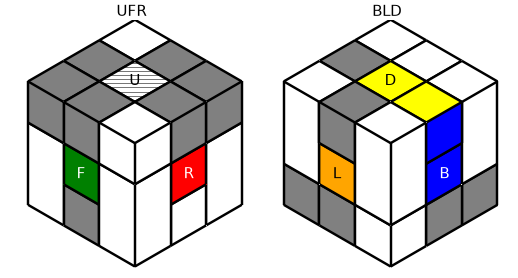

### Case 2

Execute `((((y' (M9) y)^((y' (M8) y)^-1) y' (M13) y)^-1)^((y2 (M2) y2)^-1))^-1: F2 R2 F2 R' L F L2 D2 L2 F' L' R U' R2 B2 R2 U F2 R2 F2`.

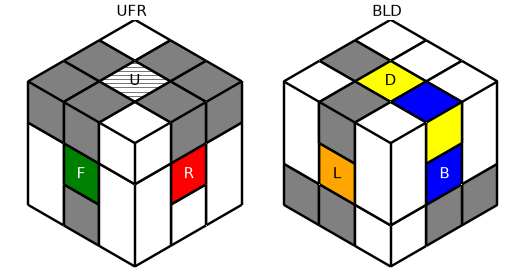

### Case 3

Execute `M35: B2 R2 B2 U L2 F2 L2 U' B2 R2 B2`.

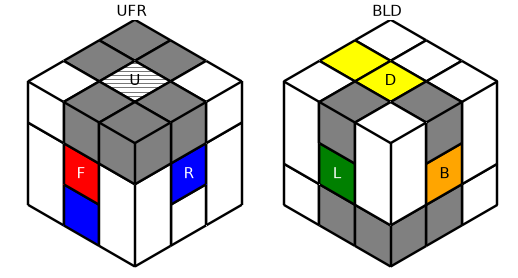

### Case 4

Execute `(y' (M9) y (y' (M8) y)^-1 y2 (M2) y2 y' (M8) y y' (M9) y)^-1: R' L' D2 L2 F' L' R F2 R2 F2 R' L F L2 D2 L R`.

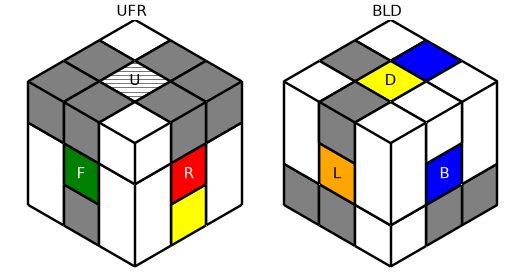

Also correct automatically after this stage: place Corner UBL; place Corner UFR; place Edge DB; place Edge DR; fully solve Edge DR.

## Stage 10: Orient Corner UBL

This stage has 3 exact cases and 2 instruction families. It reduces the remaining possibilities from 72 to 24.

### Case 1

Skip — already correct

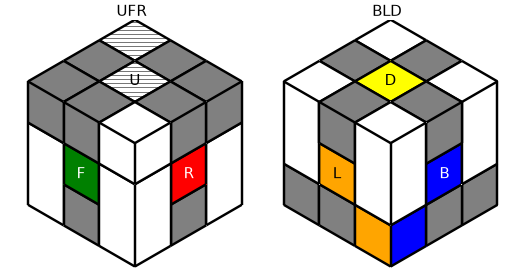

### Case 2

Execute `((((M37^-1)^(U'))^-1)^((())^-1))^-1: L2 F2 L2 U B L U L' U' B' L2 F2 L2 B U L U' L' B' U'`.

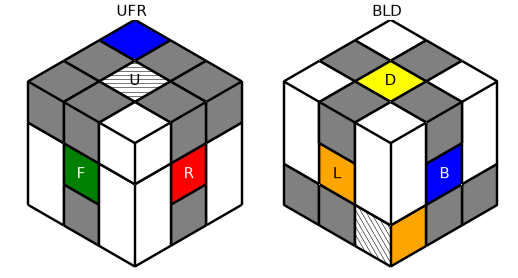

### Case 3

Execute `(((M37^-1)^(U'))^((())^-1))^-1: U B L U L' U' B' L2 F2 L2 B U L U' L' B' U' L2 F2 L2`.

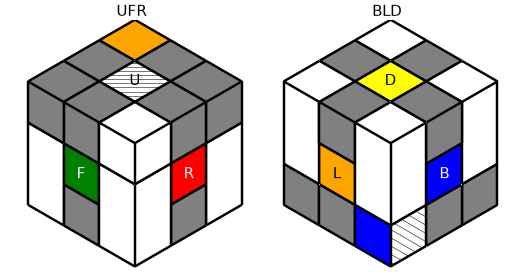

Also correct automatically after this stage: fully solve Corner UFR.

## Stage 11: Solve Pair FL-DFL

This stage has 4 exact cases and 3 instruction families. It reduces the remaining possibilities from 24 to 6.

### Case 1

Execute `M38: B U' L2 B2 U' L U2 B2 R2 B2 U2 L' U B2 L2 U B' U L' R B R' L B2 R2 B2 L' R B' R' L U'`.

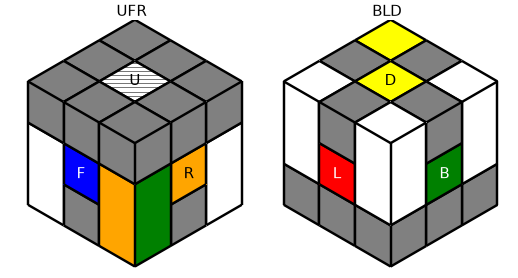

### Case 2

Execute `(M29 M9)^-1: B' F' D2 F B U B F D2 F' B' U'`.

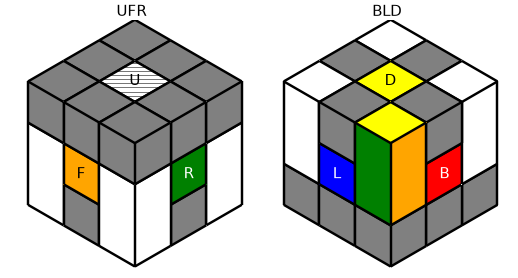

### Case 3

Skip — already correct

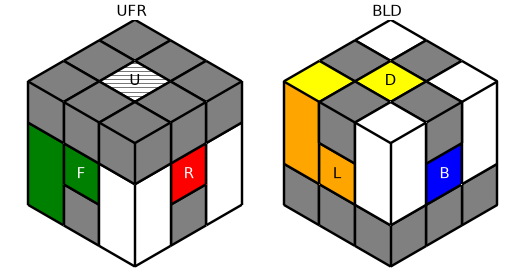

### Case 4

Execute `M38^-1: U L' R B R' L B2 R2 B2 L' R B' R' L U' B U' L2 B2 U' L U2 B2 R2 B2 U2 L' U B2 L2 U B'`.

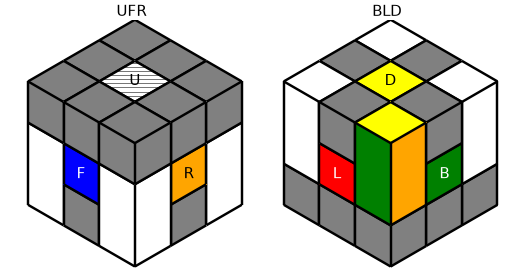

Also correct automatically after this stage: place Pair FL-DFL.

## Stage 12: Solve Pair BL-DBL

This stage has 3 exact cases and 2 instruction families. It reduces the remaining possibilities from 6 to 2.

### Case 1

Skip — already correct

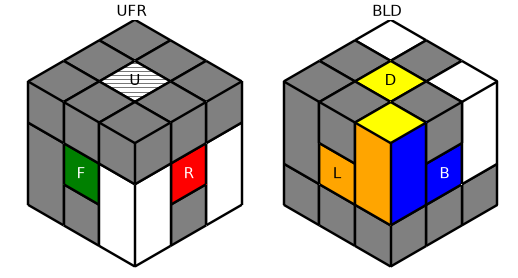

### Case 2

Execute `(y' (M29) y y' (M9) y U y' (M8) y y2 (M3) y2 (y' (M8) y)^-1 U' y2 (M23) y2 U2 y2 (M3) y2 U2 (y2 (M23) y2)^-1 y' (M9) y y' (M29) y)^-1: U R L D2 L' R' U' R' L' D2 L R F U' R2 F2 U' R U2 F2 L2 F2 U2 R' U F2 R2 U F' U R' L F L' R F2 L2 F2 R' L F' L' R U' R' L' D2 L R U R L D2 L' R' U'`.

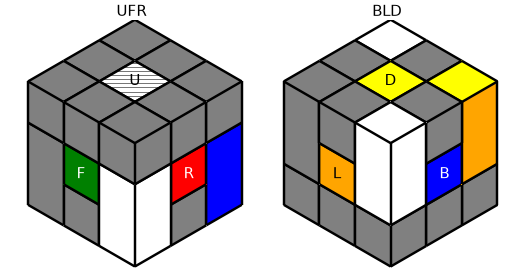

### Case 3

Execute `(y' (M29) y y' (M9) y y2 (M23) y2 U2 y2 (M3) y2 U2 (y2 (M23) y2)^-1 U y' (M8) y y2 (M3) y2 (y' (M8) y)^-1 U' y' (M9) y y' (M29) y)^-1: U R L D2 L' R' U' R' L' D2 L R U R' L F L' R F2 L2 F2 R' L F' L' R U' F U' R2 F2 U' R U2 F2 L2 F2 U2 R' U F2 R2 U F' R' L' D2 L R U R L D2 L' R' U'`.

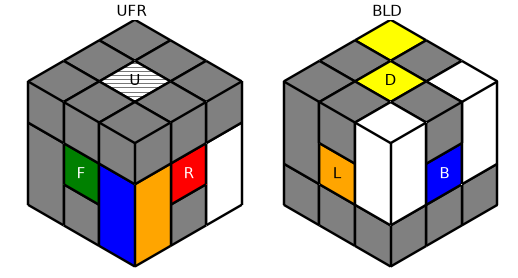

Also correct automatically after this stage: place Pair BL-DBL.

## Stage 13: Solve Pair BR-DBR

This stage has 2 exact cases and 1 instruction family. It reduces the remaining possibilities from 2 to 1.

### Case 1

Skip — already correct

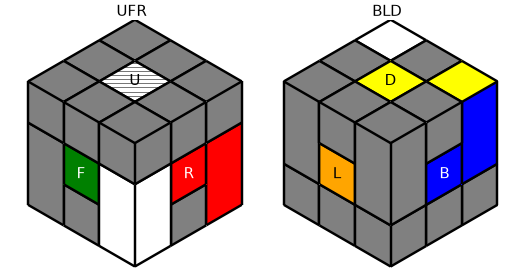

### Case 2

Execute `((U^(y' (M4) y))^-1 y2 (M33) y2 ((y2 (M2) y2)^((y (M2) y' U')^-1))^-1 (y' (M33) y)^-1 ((y2 (M3) y2)^((y2 (M2) y2 U2)^-1))^-1 y (M35) y' ((((M37^-1)^(U'))^-1)^((())^-1))^-1 y' (M29) y y' (M9) y U y' (M8) y y2 (M3) y2 (y' (M8) y)^-1 U' y2 (M23) y2 U2 y2 (M3) y2 U2 (y2 (M23) y2)^-1 y' (M9) y y' (M29) y)^-1: U R L D2 L' R' U' R' L' D2 L R F U' R2 F2 U' R U2 F2 L2 F2 U2 R' U F2 R2 U F' U R' L F L' R F2 L2 F2 R' L F' L' R U' R' L' D2 L R U R L D2 L' R' B L U L' U' B' L2 F2 L2 B U L U' L' B' U' L2 F2 B2 L2 U F2 R2 F2 U' L2 B2 L2 F2 R2 F2 U2 F2 L2 F2 U2 F2 R2 F2 R B' R' F R B R' B' F' B L2 F2 L2 U' F2 R2 F2 U L2 F2 L2 R' L R F R' F' L' F R F B2 L2 R2 U R2 L2 B2 F2`.

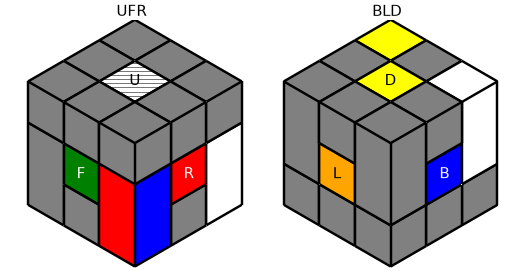

Also correct automatically after this stage: place Pair BR-DBR; place Pair FR-DFR; fully solve Pair FR-DFR.

After the final stage every modeled corner and edge sticker is solved. Unmarked center spin and independent virtual-core spin are outside this model.


In [2]:
repertoire = c.template_human_repertoire(analysis, preference=preference, backend="auto",
    optimization_seconds=120, progress=None,
)
display(Markdown(repertoire.write_guide(diagram_mode=diagram_mode, face_colors=face_colors)))


Optional shape graph. Configure and run the following cell when you want to draw the graph. `graph_view="auto"` draws small graphs and summarizes graphs above 1,000 shapes. Use `"local"` for a bounded neighborhood, or explicitly set `graph_view="full"` to draw every shape. Full layouts of large graphs can be expensive.


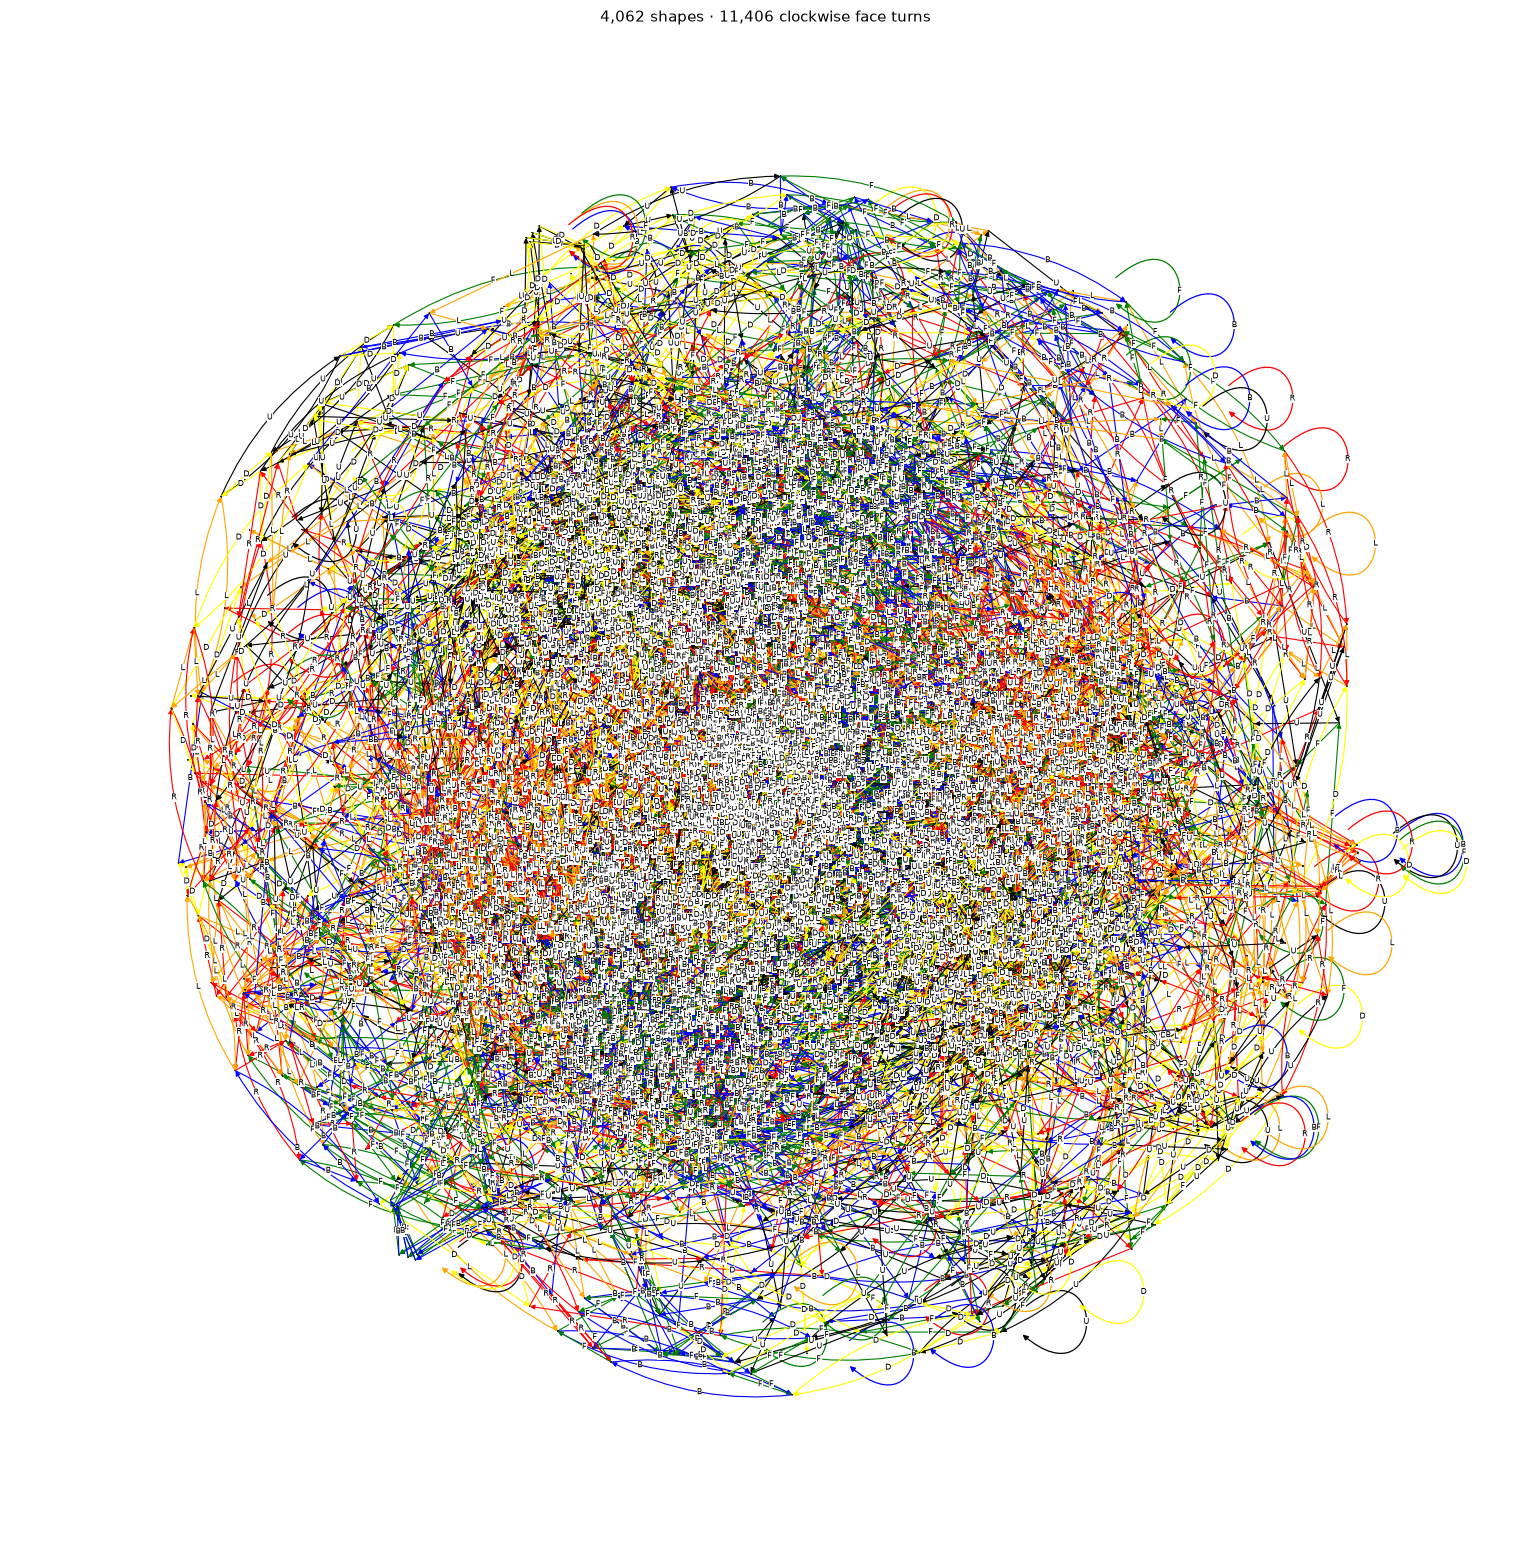

In [ ]:
import matplotlib.pyplot as plt

graph_view = "auto"  # "summary", "local", or explicit "full"
graph_max_vertices = 1000  # full auto drawings and local neighborhoods are bounded
graph_radius = 2  # used only for the local view
graph_layout = "symmetry"
graph_show_shapes = True
graph_edge_labels = True
graph_figsize = None  # automatic; override with (width, height) in inches
graph_shape_size = None  # automatic; override with a width in inches

shape_graph = c.explore(bandage)
graph_figure = c.draw_bandage_graph(
    shape_graph, view=graph_view, max_vertices=graph_max_vertices, radius=graph_radius,
    layout=graph_layout, show_shapes=graph_show_shapes,
    edge_labels=graph_edge_labels, face_colors=face_colors,
    diagram_mode=diagram_mode, figsize=graph_figsize, shape_size=graph_shape_size,
)
display(graph_figure)
plt.close(graph_figure)


## Generate a scramble

In [3]:
print(c.scramble(bandage))


R' L U2 R2 D2 U2 R2 D F2 U L B' F B' F' B' L D' B' D L2 U R' U' L' B' U' F2 D2 F2 L' U' B2 F2 D2 B' F' B' U2 F2 B' F2 U L2 R2 L2 R' B2 R' B' L U' L2 B R2 D' R' D' L D B R2 D' B L2 D' L2 F L2 B' L U L U B' U' L' F' L B D' L' D2 B2 R' U2 B2 L' D' B2 F R B2 L2 B L B D B R2
